# EDA

## Name: Cameron Mangione

## Sources

Avoidable Mortality Source from OECD: [https://data-explorer.oecd.org/vis?lc=en&pg=20&fs[0]=Topic,0%7CHealth%23HEA%23&fc=Topic&bp=true&snb=86&df[ds]=dsDisseminateFinalDMZ&df[id]=DSD_HEALTH_STAT%40DF_AM&df[ag]=OECD.ELS.HD&df[vs]=1.1&dq=.A...._T.......&pd=2010,&to[TIME_PERIOD]=false]

Healthcare Coverage Source from OECD: [https://data-explorer.oecd.org/vis?lc=en&pg=40&fs[0]=Topic,0%7CHealth%23HEA%23&fc=Topic&bp=true&snb=86&df[ds]=dsDisseminateFinalDMZ&df[id]=DSD_HEALTH_PROT%40DF_HEALTH_PROT&df[ag]=OECD.ELS.HD&df[vs]=1.1&dq=.A...&pd=2010,&to[TIME_PERIOD]=false]

Healthcare Coverage is a redundant source from our data, but I wanted to look at it in addition to the unique avoidable mortality source that I am looking at for this project.

## Imports

In [1]:
import numpy as np
import pandas as pd
import altair as alt
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
hc = pd.read_csv('healthcare_coverage.csv')
am = pd.read_csv('avoidable_mortality.csv')
hc.info()

<class 'pandas.DataFrame'>
RangeIndex: 9867 entries, 0 to 9866
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   STRUCTURE                 9867 non-null   str    
 1   STRUCTURE_ID              9867 non-null   str    
 2   STRUCTURE_NAME            9867 non-null   str    
 3   ACTION                    9867 non-null   str    
 4   REF_AREA                  9867 non-null   str    
 5   Reference area            9867 non-null   str    
 6   FREQ                      9867 non-null   str    
 7   Frequency of observation  9867 non-null   str    
 8   MEASURE                   9867 non-null   str    
 9   Measure                   9867 non-null   str    
 10  UNIT_MEASURE              9867 non-null   str    
 11  Unit of measure           9867 non-null   str    
 12  INSURANCE_TYPE            9867 non-null   str    
 13  Insurance type            9867 non-null   str    
 14  TIME_PERIOD        

## hc

The OECD healthcare coverage dataset is a slightly summarized version of the WHO healthcare coverage database. In it there is annual data from 48 different countries with 9867 observations and 30 different columns (although we will only need a small fraction of these columns for our analysis). One row in this dataset represents a country's measurement of the number of people or the percentage of people (depending on the metric) with access to healthcre, along with what kind of healthcare they have access to (government, Privte, etc.).

In [3]:
hc.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,ACTION,REF_AREA,Reference area,FREQ,Frequency of observation,MEASURE,Measure,...,OBS_STATUS2,Observation status 2,OBS_STATUS3,Observation status 3,OBS_STATUS4,Observation status 4,UNIT_MULT,Unit multiplier,DECIMALS,Decimals
0,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_PROT@DF_HEALTH_PROT(1.1),Healthcare coverage,I,NZL,New Zealand,A,Annual,HIC,Health insurance coverage,...,NaN,NaN,NaN,NaN,NaN,NaN,0,Units,1,One
1,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_PROT@DF_HEALTH_PROT(1.1),Healthcare coverage,I,NZL,New Zealand,A,Annual,HIC,Health insurance coverage,...,NaN,NaN,NaN,NaN,NaN,NaN,0,Units,1,One
2,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_PROT@DF_HEALTH_PROT(1.1),Healthcare coverage,I,NZL,New Zealand,A,Annual,HIC,Health insurance coverage,...,NaN,NaN,NaN,NaN,NaN,NaN,0,Units,1,One
3,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_PROT@DF_HEALTH_PROT(1.1),Healthcare coverage,I,NZL,New Zealand,A,Annual,HIC,Health insurance coverage,...,NaN,NaN,NaN,NaN,NaN,NaN,0,Units,1,One
4,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_PROT@DF_HEALTH_PROT(1.1),Healthcare coverage,I,NZL,New Zealand,A,Annual,HIC,Health insurance coverage,...,NaN,NaN,NaN,NaN,NaN,NaN,0,Units,1,One


### Data Cleaning

In [4]:
#Begin cleaning by making a copy of the data
clean = hc.copy()

We need the following columns in our dataset: REF_AREA has country acronyms, and makes our initial EDA plots much easier in terms of our labels. Reference area (country name), Unit of Measure tells us the method that was used, Insurance type tells us what kind of insurance there is in a given country, TIME_PERIOD is our year, OBS_VALUE is our actual values, and then UNIT_MULT and Unit Multiplier give us information on if a number is represetned in thousands or not.

All of our other columns are not needed or are missing data that is not relevant to our investigation.

In [5]:
clean_ = clean[[
       'REF_AREA','Reference area','Unit of measure','Insurance type','TIME_PERIOD','OBS_VALUE','UNIT_MULT', 'Unit multiplier']]
clean_ = clean_.rename(
    columns={
        "REF_AREA": "country_acc",
        "Reference area": "country",
        "Unit of measure": "unit_of_measure",
        "Insurance type": "insurance_type",
        "TIME_PERIOD": "year",
        "OBS_VALUE": "value",
        "UNIT_MULT": "multiplier",
        "Unit multiplier": "unit"
    }
)
clean_.info()

<class 'pandas.DataFrame'>
RangeIndex: 9867 entries, 0 to 9866
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country_acc      9867 non-null   str    
 1   country          9867 non-null   str    
 2   unit_of_measure  9867 non-null   str    
 3   insurance_type   9867 non-null   str    
 4   year             9867 non-null   int64  
 5   value            9867 non-null   float64
 6   multiplier       9867 non-null   int64  
 7   unit             9867 non-null   str    
dtypes: float64(1), int64(2), str(5)
memory usage: 616.8 KB


### Bar plot EDAs

This section has bar plots of our variables as part of our initial investigation.

#### Total Number of Country Observations

The distribution of values overall varies significantly, so we will need to be careful with filtering when using this dataset.

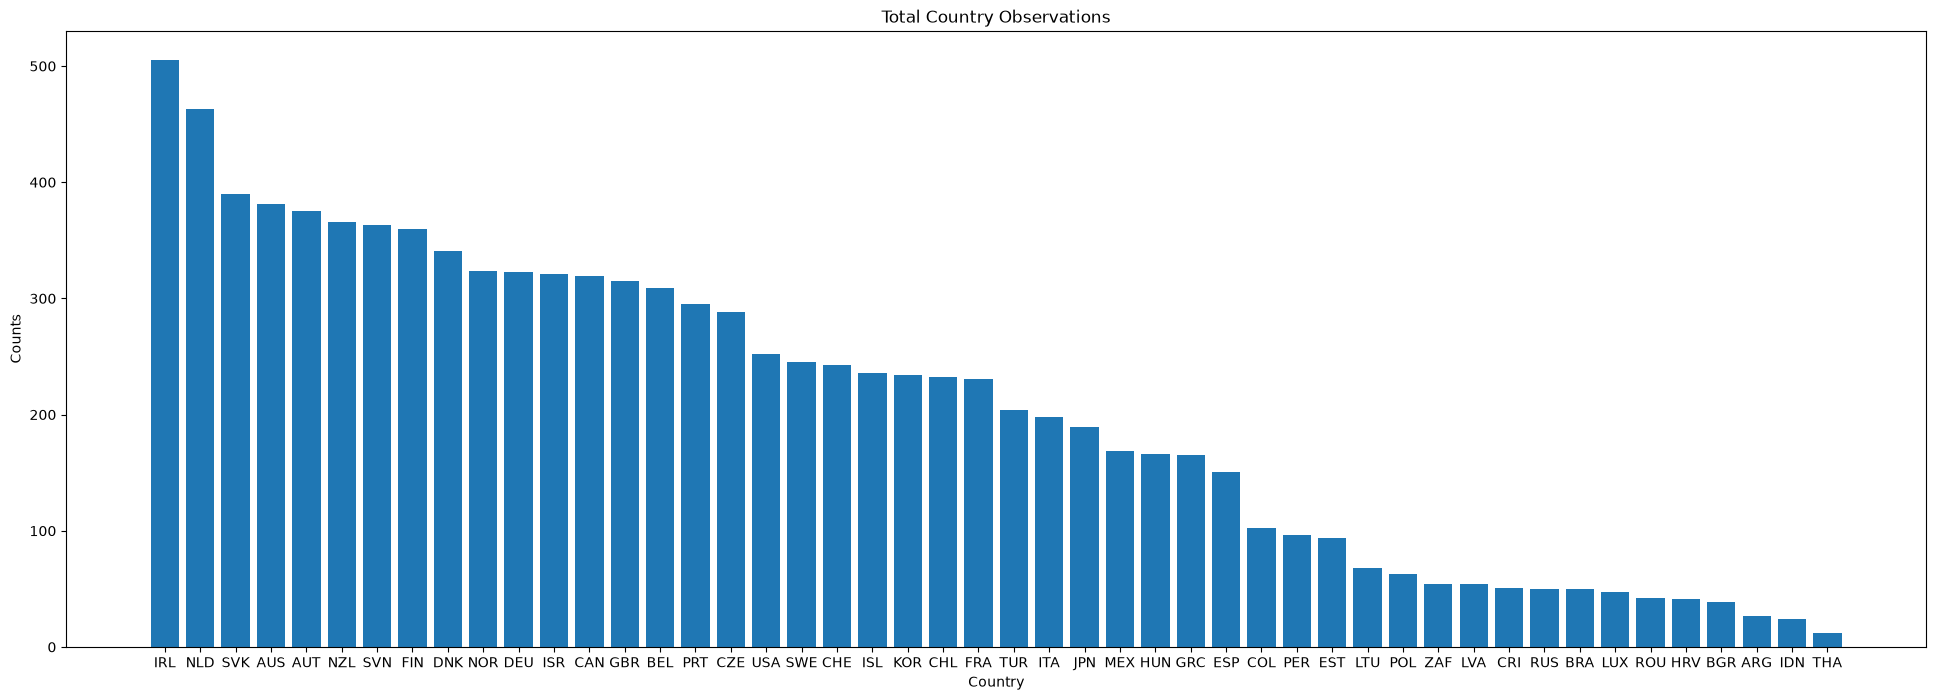

In [6]:
fig = plt.figure(figsize=(24,8))

countries, counts = np.unique(hc['REF_AREA'], return_counts=True)
sort = sorted(zip(counts, countries), reverse=True)
sorted_counts, sorted_countries = zip(*sort)

plt.bar(sorted_countries,sorted_counts)
plt.title('Total Country Observations')
plt.xlabel('Country')
plt.ylabel('Counts')

plt.show()

#### Total Number of Year Observations over time

Here we see that this dataset goes all the way back to 1960, and has a lot more observations after the year 2000.

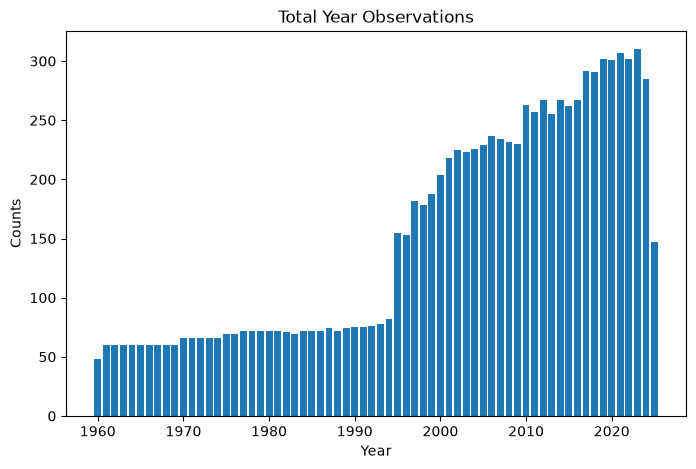

In [7]:
fig = plt.figure(figsize=(8,5))

years, counts = np.unique(clean_['year'], return_counts=True)
sort = sorted(zip(counts, years), reverse=True)
sorted_counts, sorted_years = zip(*sort)

plt.bar(sorted_years,sorted_counts)
plt.title('Total Year Observations')
plt.xlabel('Year')
plt.ylabel('Counts')

plt.show()

#### Total Unit of measurement observations

This variable could add some complications to our analysis in that it looks like there is not an even split between the two types of measurement. It will be important working this dataset that we keep in mind which kind of measurement is being used, especially since we do not have overall population data from these countries by year. This plot here will also has equivalent counts for multiplier and units. Overall, this category is very much worth filtering where we can.

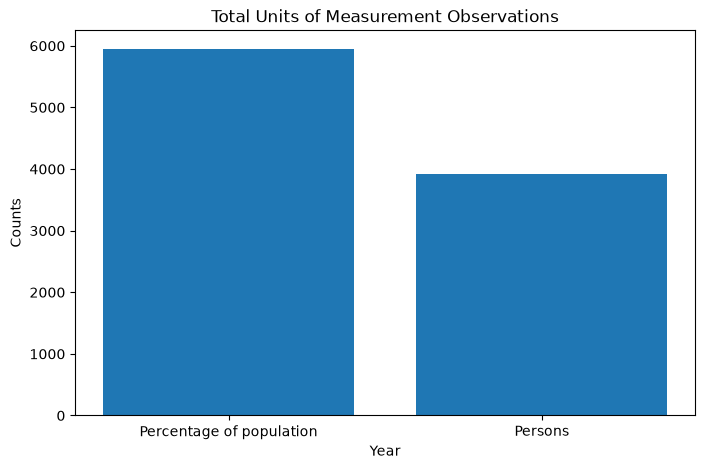

In [8]:
fig = plt.figure(figsize=(8,5))

um, counts = np.unique(clean_['unit_of_measure'], return_counts=True)
sort = sorted(zip(counts, um), reverse=True)
sorted_counts, sorted_um = zip(*sort)

plt.bar(sorted_um,sorted_counts)
plt.title('Total Units of Measurement Observations')
plt.xlabel('Year')
plt.ylabel('Counts')

plt.show()

#### Total observations by insurance type.

Insurance type is one of the more intriguing variables since it provides more information of how insurance breaks by country, which can say a lot about the data we are observing and the questions we want to answer. The COVGCMED variable describes government insurance, and seems to dominate the plot here in observations overall.

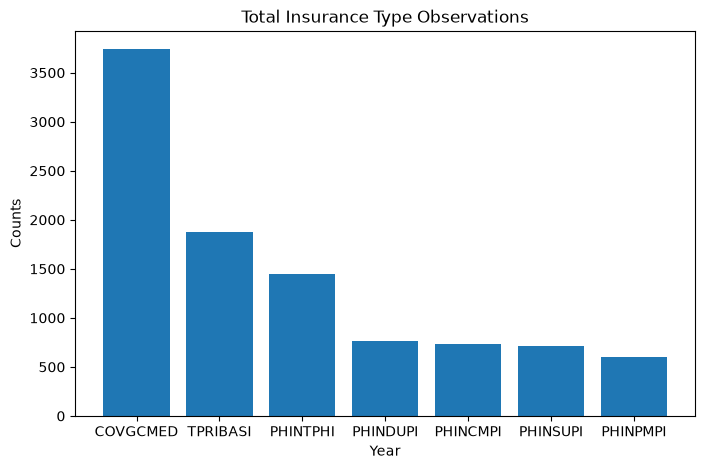

In [9]:
fig = plt.figure(figsize=(8,5))

ins, counts = np.unique(hc['INSURANCE_TYPE'], return_counts=True)
sort = sorted(zip(counts, ins), reverse=True)
sorted_counts, sorted_ins = zip(*sort)

plt.bar(sorted_ins,sorted_counts)
plt.title('Total Insurance Type Observations')
plt.xlabel('Year')
plt.ylabel('Counts')

plt.show()

#### Values EDA

Separate numeric analysis of the value variable we will be using.

In [10]:
clean_.describe()

,year,value,multiplier
count,9867.000000,9867.000000,9867.000000
mean,2003.253674,7333.104571,1.190635
std,16.819218,22786.719218,1.467826
min,1960.000000,0.000000,0.000000
25%,1995.000000,55.050000,0.000000
50%,2007.000000,100.000000,0.000000
75%,2017.000000,3397.350000,3.000000
max,2025.000000,282739.500000,3.000000


In [11]:
clean_['value'].value_counts(ascending=False)

value
100.0      2018
0.0        1050
99.9        132
99.0        129
99.8         77
           ... 
59236.0       1
59030.0       1
58997.0       1
58971.0       1
58943.0       1
Name: count, Length: 3634, dtype: int64

## hc Summary

A few things become clear when analyzing this dataset. First, there are some countries with a lot of data, and other countries that have much fewer counts overall. The distribution is also not even amongst all of the countries, so filtering by country will be important, but also filtering within those countries might end up being necessary to amke sure we have plots that work from the same sizes. Furthermore, this dataset has around 10k points, which made using Altair for EDA difficult with its 5000 row limit. Within the entire dataset, it looks like there are a lot more government insurance coverages overall, so it's worth investigating which countries use this, if any trends change over time, and also how countries compare against each other (with a specific focus on the US compared to other allies and countries). 

Ideally this dataset would be combined with other numberic variable types since this data has one true numeric variable in it, which makes for a limited number of expressive plots on its own. I'd say I'm very interested in plotting different kinds of relationships between the avoidable amortality groups versus helthcare coverage because I think it has the potential to show key insights around how the USA's greed in healthcare coverage creates more preventable deaths.

## am

The OECD avoidable mortality dataset is a slightly siummarized version of the WHO avoidable mortality database. Within the database there is data on 46 different countries and 18810 observations by 44 columns of the different levels of avoidable mortality by country for a given year. Onee row represents a specific kind of mortality type for a country in a given year.

Per the OECD:

This dataset presents data on preventable, treatable and avoidable (preventable + treatable) causes of mortality. Preventable and treatable causes of mortality are defined as follows:

- Preventable mortality: Causes of death that can be mainly avoided through effective public health and primary prevention interventions (i.e. before the onset of diseases/injuries, to reduce incidence).
- Treatable (or amenable) mortality: Causes of death that can be mainly avoided through timely and effective healthcare interventions, including secondary prevention such as screening, and treatment (i.e. after the onset of diseases, to reduce case-fatality).

Both indicators refer to premature mortality (under age 75).

In [12]:
am.info()

<class 'pandas.DataFrame'>
RangeIndex: 18810 entries, 0 to 18809
Data columns (total 44 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   STRUCTURE                   18810 non-null  str    
 1   STRUCTURE_ID                18810 non-null  str    
 2   STRUCTURE_NAME              18810 non-null  str    
 3   ACTION                      18810 non-null  str    
 4   REF_AREA                    18810 non-null  str    
 5   Reference area              18810 non-null  str    
 6   FREQ                        18810 non-null  str    
 7   Frequency of observation    18810 non-null  str    
 8   MEASURE                     18810 non-null  str    
 9   Measure                     18810 non-null  str    
 10  UNIT_MEASURE                18810 non-null  str    
 11  Unit of measure             18810 non-null  str    
 12  AGE                         18810 non-null  str    
 13  Age                         18810 non-null

In [13]:
am.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation', 'MEASURE',
       'Measure', 'UNIT_MEASURE', 'Unit of measure', 'AGE', 'Age', 'SEX',
       'Sex', 'SOCIO_ECON_STATUS', 'Socio-economic status', 'DEATH_CAUSE',
       'Cause of death', 'CALC_METHODOLOGY', 'Calculation methodology',
       'GESTATION_THRESHOLD', 'Gestation period threshold', 'HEALTH_STATUS',
       'Health status', 'DISEASE', 'Disease', 'CANCER_SITE', 'Cancer site',
       'TIME_PERIOD', 'Time period', 'OBS_VALUE', 'Observation value',
       'DECIMALS', 'Decimals', 'OBS_STATUS', 'Observation status',
       'OBS_STATUS2', 'Observation status 2', 'OBS_STATUS3',
       'Observation status 3', 'UNIT_MULT', 'Unit multiplier'],
      dtype='str')

### Data Cleaning

In [14]:
clean2 = am.copy()
clean2.isna().sum()

STRUCTURE                         0
STRUCTURE_ID                      0
STRUCTURE_NAME                    0
ACTION                            0
REF_AREA                          0
Reference area                    0
FREQ                              0
Frequency of observation          0
MEASURE                           0
Measure                           0
UNIT_MEASURE                      0
Unit of measure                   0
AGE                               0
Age                               0
SEX                               0
Sex                               0
SOCIO_ECON_STATUS                 0
Socio-economic status             0
DEATH_CAUSE                       0
Cause of death                    0
CALC_METHODOLOGY                  0
Calculation methodology           0
GESTATION_THRESHOLD               0
Gestation period threshold        0
HEALTH_STATUS                     0
Health status                     0
DISEASE                           0
Disease                     

The key thing to note in our NaN analysis here is that we have 30 year observations (*not 30 full years*) missing and 30 values missing. This is a small fraction of our total data (30/18810), so we will proceed with dropping these values.

Like the healthcare coverage dataset, we will keep both reference areas for easier plotting, the measure for type of mortality, the unit of measure so we can use the proper data in our filters, TIME_PERIOD for year, and OBS_VALUE for the values in each case. TIME_PERIOD was also imported in as a float, so for the time being we will convert it to an integer since our data does not have months or days or other time measures in it.

All of our other columns are not needed or are missing data that is not relevant to our investigation.

In [15]:
clean2_ = clean2[["REF_AREA",'Reference area','Measure','Unit of measure',
       'Sex',
       'TIME_PERIOD', 'OBS_VALUE']]
clean2_ = clean2_.rename(
    columns={
        "REF_AREA": "country_acc",
        "Reference area": "country",
        "Measure": "mortality_type",
        "Unit of measure": "unit_measure",
        "TIME_PERIOD": "year",
        "OBS_VALUE": "value"
    })
clean2_ = clean2_.dropna()
clean2_['year'] = clean2_['year'].astype(int)
clean2_.head(1)

,country_acc,country,mortality_type,unit_measure,Sex,year,value
0,AUS,Australia,Treatable mortality,Deaths,Total,2000,14337.0


### Bar plot EDAs

This section has bar plots of our variables as part of our initial investigation.

#### Total Number of Country Observations

In contrast to the healthcare coverage, we have a more even and somewhat uniform distribution of country values, which should make plotting and analysis between countries easier overall. Canada and the US also seem fairly close in value here.

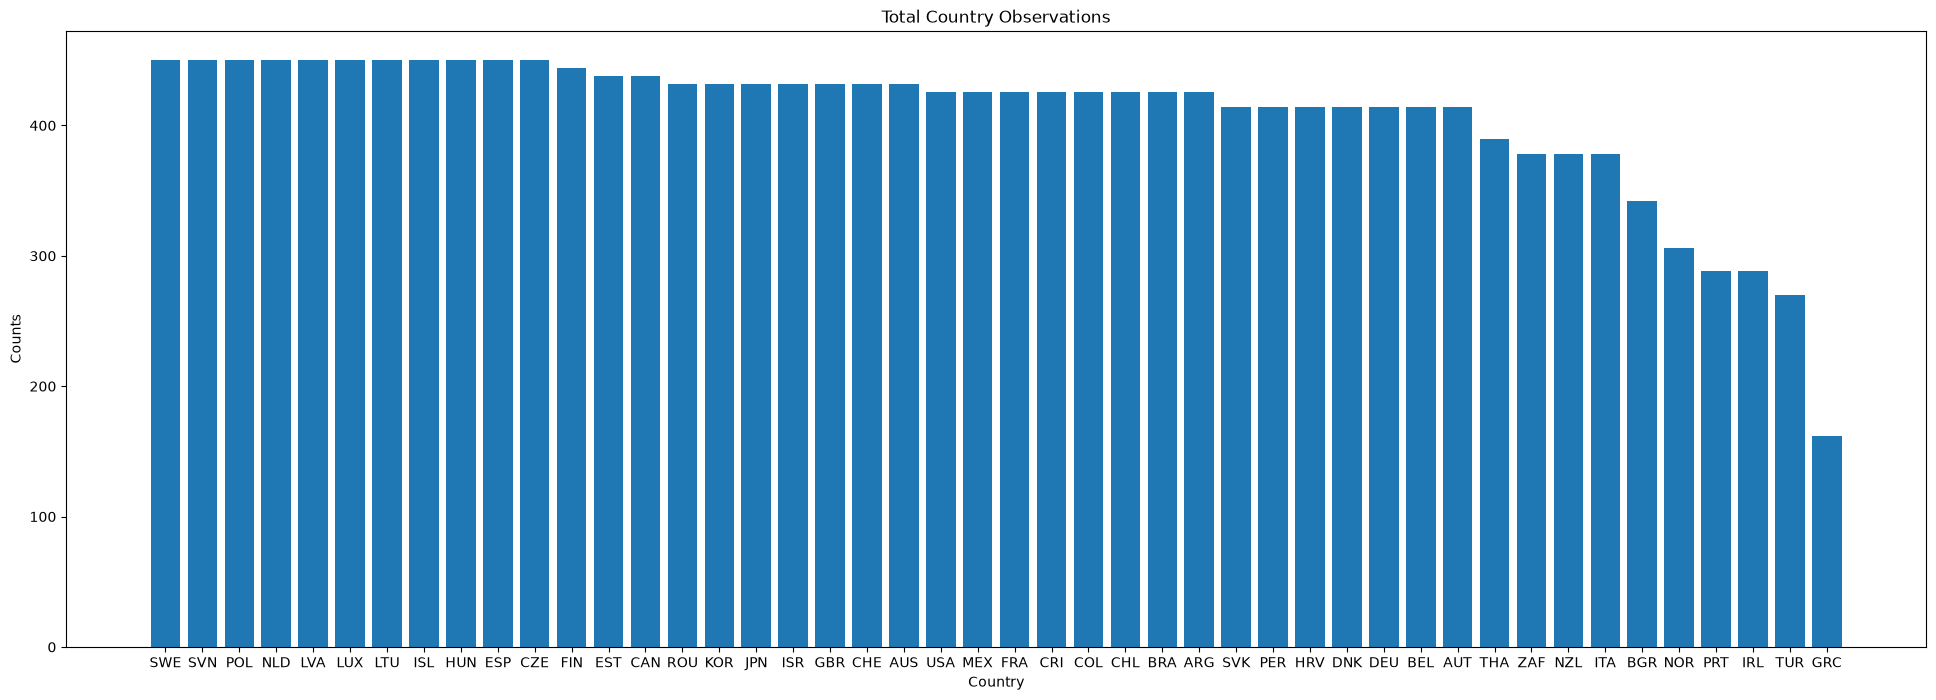

In [16]:
fig = plt.figure(figsize=(24,8))

countries2, counts2 = np.unique(clean2_['country_acc'], return_counts=True)
sort2 = sorted(zip(counts2, countries2), reverse=True)
sorted_counts2, sorted_countries2 = zip(*sort2)

plt.bar(sorted_countries2,sorted_counts2)
plt.title('Total Country Observations')
plt.xlabel('Country')
plt.ylabel('Counts')

plt.show()

#### Total Number of Year Observations over time

Here we see that this dataset only goes to 200 in contrast to the healthcare coverage dataset, and has a fairly uniform distribution of with exception for 2023-2025 having either low or no obersvations, so limiting our study a certain range might be useful with this in mind.

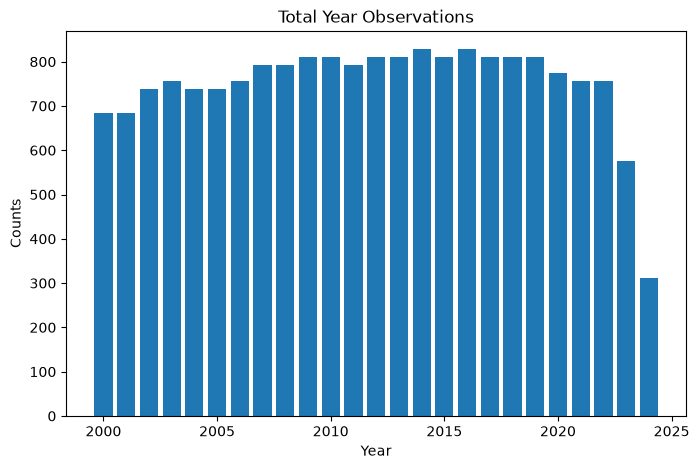

In [17]:
fig = plt.figure(figsize=(8,5))

years2, counts2 = np.unique(clean2_['year'], return_counts=True)
sort = sorted(zip(counts2, years2), reverse=True)
sorted_counts2, sorted_years2 = zip(*sort)

plt.bar(sorted_years2,sorted_counts2)
plt.title('Total Year Observations')
plt.xlabel('Year')
plt.ylabel('Counts')

plt.show()

#### Total Sex Observations

Sex is fairly evenly split, with total being a bit higher. This variable may or may not be useful, and the aggregation group may make things complicated if we compare these three groups directly. Context likely matters a lot here.

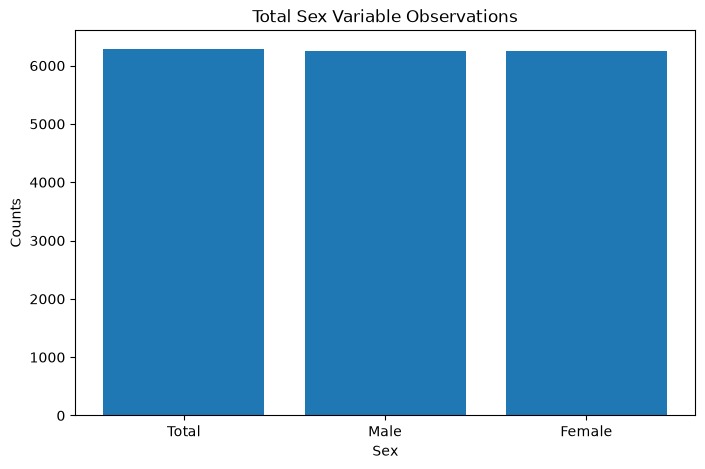

In [18]:
fig = plt.figure(figsize=(8,5))

sex, counts = np.unique(clean2_['Sex'], return_counts=True)
sort = sorted(zip(counts, sex), reverse=True)
sorted_counts, sorted_sex = zip(*sort)

plt.bar(sorted_sex,sorted_counts)
plt.title('Total Sex Variable Observations')
plt.xlabel('Sex')
plt.ylabel('Counts')

plt.show()

#### Total Mortality Type Observations

The mortality groups seems evenly split into three groups, which should make this a great filter for our plots that we want to make within this dataset.

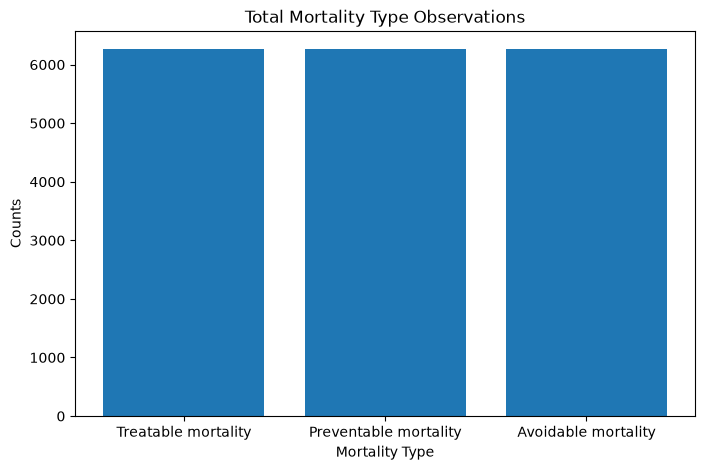

In [19]:
fig = plt.figure(figsize=(8,5))

measure, counts = np.unique(clean2_['mortality_type'], return_counts=True)
sort = sorted(zip(counts, measure), reverse=True)
sorted_counts, sorted_am = zip(*sort)

plt.bar(sorted_am,sorted_counts)
plt.title('Total Mortality Type Observations')
plt.xlabel('Mortality Type')
plt.ylabel('Counts')

plt.show()

#### Total Units of Measurement Observations

Unit of measurement is also split mostly in half, which makes it likely more straightforward to filter compared to the healthcare plot.

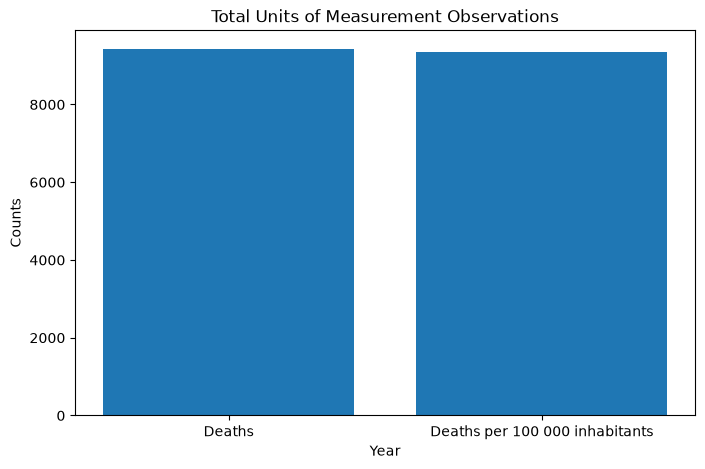

In [20]:
fig = plt.figure(figsize=(8,5))

um2, counts2 = np.unique(clean2_['unit_measure'], return_counts=True)
sort = sorted(zip(counts2, um2), reverse=True)
sorted_counts2, sorted_um2= zip(*sort)

plt.bar(sorted_um2,sorted_counts2)
plt.title('Total Units of Measurement Observations')
plt.xlabel('Year')
plt.ylabel('Counts')

plt.show()

### Value analysis

While not plotting for this variable directly, it is clear that the range for this variable is broad due to the split measurement types, so detailed fitlering will be needed to plot this variable.

In [21]:
clean2_.describe()

,year,value
count,18780.000000,1.878000e+04
mean,2011.783387,2.194666e+04
std,6.863270,6.526663e+04
min,2000.000000,3.300000e+01
25%,2006.000000,1.500000e+02
50%,2012.000000,5.405000e+02
75%,2018.000000,1.376000e+04
max,2024.000000,1.281339e+06


In [22]:
clean2_['value'].value_counts(ascending=False)

value
79.0     64
83.0     61
67.0     60
133.0    58
86.0     57
         ..
534.0     1
672.0     1
685.0     1
660.0     1
634.0     1
Name: count, Length: 8834, dtype: int64

In [23]:
clean2_[clean2_['unit_measure'] == 'Deaths per 100 000 inhabitants']['value'].value_counts()

value
79.0     60
83.0     59
67.0     59
133.0    58
86.0     56
         ..
475.0     1
672.0     1
685.0     1
660.0     1
634.0     1
Name: count, Length: 718, dtype: int64

In [24]:
clean2_[clean2_['unit_measure'] == 'Deaths']['value'].value_counts()

value
178.0      7
132.0      7
1621.0     5
174.0      5
177.0      5
          ..
79759.0    1
84124.0    1
93566.0    1
91475.0    1
82894.0    1
Name: count, Length: 8410, dtype: int64

## am summary

One downside to this dataset is that ist has 18k+ observations and splits down into three 6k observations splits for the mortality types, so ALtair is realisitically only usable when filtered aggressively, which is bad for EDA and also might be less than ideal for what we want to show as our final plots too.

I think the relationships of the mortality rates is very important explore effectively because this dataset really shows how the type of healthcare coverage that you use can have major impacts on the survival likelihood in a given country. I also want to see how it relates to healthcare expenditures as well.

For the investigation above to work, merging with a healthcare coverage, and expenditure dataset would be useful but could also be difficult in practice as well in esnuring that data is preserved in the merging. Ideally, I'd love to be able to make some scatter plots between percentage insured and avoidable mortality could be fascinating to see, or avoidable mortality and average healthcare cost in a given category could be intriguing too.